# Notebook 04: Aspect-based sentiment analysis

**Goal:** go beyond one score per review and find out **what** customers like or dislike: battery, camera, price, delivery and so on.

**Input:** `data/processed/reviews_electronics_clean.csv` and the model saved by notebook 03 (`models/best_model.pkl`)
**Output:** `reports/aspect_sentiment.csv`, `reports/aspect_sentiment.png`

**Why this matters:** the review "camera is great but battery is bad" is positive about one thing and negative about another. A single "neutral" score hides both facts. A seller reading thousands of reviews wants to know "battery: 40% negative", not just "overall 78% positive".

**What we do, in order**
1. Load the data and the trained model
2. See how we split reviews into clauses and spot aspects (a keyword method)
3. Extract aspect clauses from all reviews
4. Score the sentiment of each clause with our model
5. Summarise sentiment per aspect and draw a chart
6. Check the quality by reading real examples
7. Drill down into one product
8. Save the results

## Step 0: Setup

In [1]:
import os, sys
root = os.getcwd() if os.path.isdir("src") else os.path.abspath("..")
os.chdir(root)
sys.path.insert(0, root)

import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from src.preprocess import clean_text
from src.aspects import ASPECTS, split_clauses, find_aspects, extract_aspect_clauses

pd.set_option("display.max_colwidth", 100)
LABELS = ["negative", "neutral", "positive"]

## Step 1: Load the data and the trained model

We reuse the vectorizer and classifier saved in notebook 03, so the whole project is one connected pipeline: the same model that scores whole reviews now scores pieces of reviews.

In [2]:
elec = pd.read_csv("data/processed/reviews_electronics_clean.csv")
elec = elec.dropna(subset=["Summary"]).reset_index(drop=True)

vec, model = joblib.load("models/best_model.pkl")
print(len(elec), "reviews loaded; model type:", type(model).__name__)

67401 reviews loaded; model type: LinearSVC


## Step 2: How we find aspects

Our method has two simple parts. You can read the code in `src/aspects.py`.

1. **Split a review into clauses** at punctuation and words like "but" / "however", so each clause talks about roughly one thing.
2. **Match keywords:** each aspect has a list of keywords (for example battery: "battery", "backup", "charging"). If a clause contains one, the clause is about that aspect.

This is a *dictionary (keyword) method*. Its strength is that it is transparent and easy to check. Its weakness is that it can only find aspects whose words we listed.

Here are our aspects and an example of the method in action:

In [3]:
print("Aspects:", ", ".join(ASPECTS))
print()
for text in ["Camera is great but battery is bad",
             "Good phone, fast delivery and nice display",
             "sound and picture quality is good",
             "super"]:
    print(repr(text))
    print("   clauses:", split_clauses(text))
    print("   aspects:", extract_aspect_clauses(text))

Aspects: battery, camera, display, sound, performance, price, build quality, design, connectivity, delivery, heating, cooling, noise

'Camera is great but battery is bad'
   clauses: ['camera is great', 'battery is bad']
   aspects: [('camera', 'camera is great'), ('battery', 'battery is bad')]
'Good phone, fast delivery and nice display'
   clauses: ['good phone', 'fast delivery', 'nice display']
   aspects: [('delivery', 'fast delivery'), ('display', 'nice display')]
'sound and picture quality is good'
   clauses: ['sound and picture quality is good']
   aspects: [('display', 'sound and picture quality is good'), ('sound', 'sound and picture quality is good')]
'super'
   clauses: ['super']
   aspects: []


**What to notice:** the first review becomes two clauses with different aspects. The last review ("super") mentions no aspect, so it gives nothing; that is normal, since many reviews are just a general comment.

## Step 3: Extract aspect clauses from all reviews

For each review we collect every `(aspect, clause)` pair. Then we attach the product name and star rating so we can analyse by product later.

In [4]:
records = []
for review_id, text in zip(elec.index, elec["Summary"].astype(str)):
    for aspect, clause in extract_aspect_clauses(text):
        records.append((review_id, aspect, clause))

clauses = pd.DataFrame(records, columns=["review_id", "aspect", "clause"])
clauses = clauses.join(elec[["product_name", "Rate", "label"]], on="review_id")

covered = clauses["review_id"].nunique()
print(f"{covered} of {len(elec)} reviews ({covered / len(elec):.1%}) mention at least one aspect")
print(len(clauses), "aspect mentions in total")
clauses["aspect"].value_counts()

27962 of 67401 reviews (41.5%) mention at least one aspect
46114 aspect mentions in total


aspect
price            10299
sound             6817
build quality     6757
design            3893
performance       3816
delivery          3636
battery           2898
connectivity      2605
display           1744
heating           1468
camera             871
noise              793
cooling            517
Name: count, dtype: int64

**What to notice:** only a part of the reviews mention a specific aspect. Most are general ("good", "nice product"). That is a real property of this data, and a fair limitation to mention in your report.

## Step 4: Score the sentiment of each clause

We clean each clause exactly like the training data (`clean_text`) and let the model predict its sentiment. We skip clauses with fewer than 2 words after cleaning ("battery" alone says nothing about sentiment).

*Important idea:* the model was trained on whole reviews, but it still works reasonably on short clauses because the sentiment words ("bad", "great") are what it relies on.

In [5]:
clauses["clean"] = clauses["clause"].apply(clean_text)
clauses = clauses[clauses["clean"].str.split().str.len() >= 2].copy()

clauses["sentiment"] = model.predict(vec.transform(clauses["clean"]))
print(len(clauses), "clauses scored")
clauses["sentiment"].value_counts(normalize=True).round(3)

45935 clauses scored


sentiment
positive    0.783
negative    0.169
neutral     0.048
Name: proportion, dtype: float64

## Step 5: Sentiment per aspect

For each aspect we count its mentions and compute the share of positive, neutral and negative clauses. The **net score** is `% positive minus % negative`: above 0 means customers are mostly happy about that aspect, below 0 means mostly unhappy.

*A caution:* our model is weakest on the **neutral** class, so read the net score (positive vs negative) more than the neutral share.

In [6]:
counts = pd.crosstab(clauses["aspect"], clauses["sentiment"]).reindex(columns=LABELS, fill_value=0)
mentions = counts.sum(axis=1)
pct = counts.div(mentions, axis=0) * 100

summary = pct.round(1)
summary["mentions"] = mentions
summary["net_score"] = (pct["positive"] - pct["negative"]).round(1)
summary = summary.sort_values("net_score", ascending=False)
summary

sentiment,negative,neutral,positive,mentions,net_score
aspect,,,,,
delivery,9.0,1.7,89.3,3635,80.3
design,7.9,4.3,87.7,3888,79.8
price,12.5,2.2,85.3,10221,72.8
performance,13.7,5.5,80.7,3804,67.0
cooling,12.8,9.7,77.5,516,64.7
sound,16.6,5.3,78.0,6789,61.4
camera,18.6,4.5,76.9,871,58.3
display,18.0,8.3,73.8,1742,55.8
build quality,20.6,4.3,75.2,6747,54.6


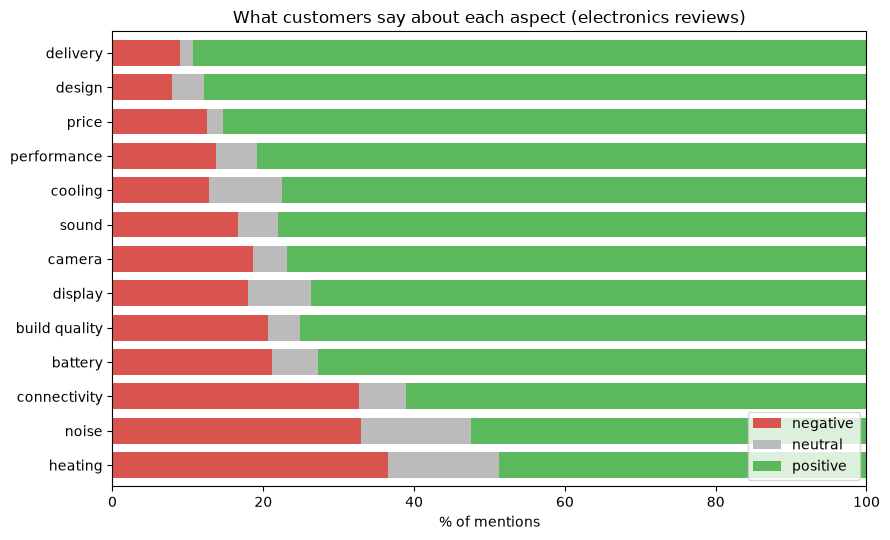

In [7]:
plot_df = summary.sort_values("net_score")[LABELS]
colors = {"negative": "#d9534f", "neutral": "#bbbbbb", "positive": "#5cb85c"}

ax = plot_df.plot(kind="barh", stacked=True, figsize=(9, 5.5),
                  color=[colors[c] for c in LABELS], width=0.75)
ax.set_xlabel("% of mentions")
ax.set_ylabel("")
ax.set_title("What customers say about each aspect (electronics reviews)")
ax.set_xlim(0, 100)
ax.legend(loc="lower right")
plt.tight_layout()

os.makedirs("reports", exist_ok=True)
plt.savefig("reports/aspect_sentiment.png", dpi=150)
plt.show()

**What to notice:** aspects at the top of the table are praised, aspects at the bottom have the most complaints. Think about *why*: for example, a "heating" or "delivery" mention is usually a complaint, because people mostly mention them when something goes wrong.

## Step 6: Check the quality by reading real examples

Never trust a number you have not checked against real text. Read the sample below and count how many predictions you agree with. A simple, honest report line is: "I manually checked 30 random aspect clauses and agreed with X of 30".

In [8]:
check = clauses.sample(min(30, len(clauses)), random_state=5)
check[["aspect", "clause", "sentiment"]].reset_index(drop=True)

,aspect,clause,sentiment
0,connectivity,not for best house is only operate wifi not a hotspot,negative
1,performance,the speed is only 35mbps,positive
2,sound,very nice product amazing bass lovely sound quality,positive
3,delivery,1st day review nice packaging,positive
4,battery,sometimes there is distortion when its bluetooth is on and its battery i dont know why it goes f...,neutral
5,price,weigh less and not foldableworth and value for money got it for 1299 on o,negative
6,price,low budget good looking for show off not too much working,neutral
7,design,good cooler it occupies more space looks very large,positive
8,battery,battery drain very fast within 30 min on high volume also build quality is not good,negative
9,build quality,good product super quality,positive


**Write down:** how many of the 30 do you agree with? What kinds of mistakes do you see (clauses with no sentiment word, sarcasm, wrong aspect matched)?

## Step 7: Drill down into one product

This is what a seller or a buyer would actually want: the aspect profile of **one product**. Below we pick the product with the most reviews. Change `product` to any product name from your data.

In [9]:
def aspect_report(product, min_mentions=10):
    """Aspect sentiment table for one product (exact product name)."""
    sub = clauses[clauses["product_name"] == product]
    c = pd.crosstab(sub["aspect"], sub["sentiment"]).reindex(columns=LABELS, fill_value=0)
    total = c.sum(axis=1)
    out = (c.div(total, axis=0) * 100).round(1)
    out["mentions"] = total
    out["net_score"] = (out["positive"] - out["negative"]).round(1)
    return out[out["mentions"] >= min_mentions].sort_values("net_score", ascending=False)

product = clauses["product_name"].value_counts().index[0]
print("Product:", product[:90])
aspect_report(product)

Product: Mi 5A 80 cm (32 inch) HD Ready LED Smart Android TV with Dolby Audio (2022 Model)


sentiment,negative,neutral,positive,mentions,net_score
aspect,,,,,
price,6.6,0.8,92.6,769,86.0
delivery,10.3,0.4,89.3,253,79.0
design,6.9,8.6,84.5,116,77.6
sound,10.3,4.8,84.9,544,74.6
build quality,12.1,6.2,81.7,289,69.6
display,15.8,6.4,77.8,730,62.0
performance,26.1,9.4,64.5,138,38.4
connectivity,29.0,8.3,62.7,459,33.7
battery,40.9,4.5,54.5,22,13.6


If the table is short, that product has few aspect mentions. Try another product, or lower `min_mentions`.

## Step 8: Save the results

In [10]:
summary.to_csv("reports/aspect_sentiment.csv")
clauses[["review_id", "product_name", "aspect", "clause", "sentiment"]].to_csv(
    "data/processed/aspect_clauses.csv", index=False)
print("saved reports/aspect_sentiment.csv and data/processed/aspect_clauses.csv")

saved reports/aspect_sentiment.csv and data/processed/aspect_clauses.csv


In [11]:
import os, pandas as pd
root = os.getcwd() if os.path.isdir("src") else os.path.abspath("..")
os.chdir(root)

c = pd.read_csv("data/processed/aspect_clauses.csv")
d = c[c["aspect"] == "delivery"]
for kw in ["deliver", "packag", "packing", "packed", "seller", "courier"]:
    print(kw, d["clause"].str.contains(kw).sum())
d.sample(15, random_state=1)[["clause", "sentiment"]]

deliver 2974
packag 365
packing 280
packed 107
seller 163
courier 51


,clause,sentiment
25618,dlink gives quite a better speed than tplink very happy with this product flipkart delivered it ...,positive
18101,got a timely delivery,positive
9472,all proved useless it works well and remote is original thanks flipkart and the seller,positive
39740,very good installation and fast delivery thank you flipkart its complete my kitchen,positive
39777,nice product installation and delivery done on proper time,positive
9174,have been using it for a couple of days excellent delivery installation experience great product...,positive
24106,very good product i am so happy fast delivery,positive
26661,nice swing machine and good condition to deliver thank you flipkart and dealers,positive
44314,great product value of money delivery too fast just in 3 days amazing,positive
42014,great product does the job as promised amazing delivery product came within 24 hours,positive


## Limitations 

- **Keyword method:** an aspect is found only if one of our listed words appears. New words or Hinglish are missed.
- **Many reviews have no aspect:** most reviews are general comments.
- **Model trained on whole reviews:** it scores clauses reasonably but not perfectly, especially the neutral class.
- **Matching can be wrong:** "hot" in "hot deal" would be tagged as heating; "range" in a price range would be tagged as connectivity.

**Ways to improve (future work):** learn aspects automatically with topic models or a transformer, and train on aspect-labelled data.

**Next:** a transformer model (DistilBERT) to compare with the classical models, and a small app to try reviews live.